# Porto Seguro Safe Driver Prediction – 01 Exploratory Data Analysis

**Question:** what does the data look like, which quality issues does it have, and which features are
related to the target (a driver filing an insurance claim within a year)? Every finding is turned into a
decision for the preparation and modelling notebooks.

**Data:** `train.csv` of the Kaggle competition
[Porto Seguro's Safe Driver Prediction](https://www.kaggle.com/competitions/porto-seguro-safe-driver-prediction).
Only this file is used, because the Kaggle `test.csv` has no target. It is split into a training part and a
held-out test part; all exploration is done on the training part only.

**Workflow**
1. Setup: imports, paths, random seed, library versions
2. Load and describe the data
3. Recode missing values (`-1` → NaN)
4. Train/test split (stratified 80/20)
5. Target balance
6. Missing values: how many, and are they informative?
7. Feature types and distributions
8. Features vs target (univariate Gini, noise reference)
9. Correlations between features
10. Duplicates and leakage check
11. Summary of findings and EDA log

## 1. Setup

In [1]:
# 1. Imports, shared constants and library versions
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.metrics import roc_auc_score

# shared project code lives in ../src (same loading and split for every notebook)
sys.path.insert(0, str(Path.cwd().parent))
from src.data_utils import DATA_PATH, MISSING_CODE, RANDOM_STATE, train_test_parts

plt.rcParams['figure.dpi'] = 90

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")

Python 3.14.4 | numpy 2.4.4 | pandas 3.0.2 | scikit-learn 1.8.0 | matplotlib 3.10.8


## 2. Load and describe the data

In [2]:
# 2. Load the raw training file (read only, never overwritten)
raw_data = pd.read_csv(DATA_PATH)
raw_data.head()

,id,target,ps_ind_01,ps_ind_02_cat,ps_ind_03,ps_ind_04_cat,ps_ind_05_cat,ps_ind_06_bin,ps_ind_07_bin,ps_ind_08_bin,...,ps_calc_11,ps_calc_12,ps_calc_13,ps_calc_14,ps_calc_15_bin,ps_calc_16_bin,ps_calc_17_bin,ps_calc_18_bin,ps_calc_19_bin,ps_calc_20_bin
0,7,0,2,2,5,1,0,0,1,0,...,9,1,5,8,0,1,1,0,0,1
1,9,0,1,1,7,0,0,0,0,1,...,3,1,1,9,0,1,1,0,1,0
2,13,0,5,4,9,1,0,0,0,1,...,4,2,7,7,0,1,1,0,1,0
3,16,0,0,1,2,0,0,1,0,0,...,2,2,4,9,0,0,0,0,0,0
4,17,0,0,2,0,1,0,1,0,0,...,3,1,1,3,0,0,0,1,1,0


In [3]:
# 2. Size of the data and data types
print(raw_data.shape)
print(raw_data.dtypes.value_counts())

(595212, 59)
int64      49
float64    10
Name: count, dtype: int64


All 59 columns are numeric: `id`, the binary `target` and 57 anonymised features.
The meaning of the features is not published; only their names tell the group (`ind`, `reg`, `car`, `calc`)
and the type (section 7).

## 3. Recode missing values
According to the competition description, missing values are encoded as `-1`.

In [4]:
# 3. Replace the -1 code with NaN
data = raw_data.replace(MISSING_CODE, np.nan)

# check: no other negative values remain, so -1 was the only negative code
print((data.drop(columns=['id']).min() >= 0).all())

True


`-1` is the only negative value in the data, so it can safely be treated as "missing".
The notebooks 02–04 use `load_data()` from `src/data_utils.py`, which applies exactly this recoding.

## 4. Train/test split
Stratified 80/20 split, so both parts keep the same claim rate. The test part is held out until the final
evaluation; it is used here only for the leakage check in section 10, never for exploring the target.

In [5]:
# 4. Split features and target, then stratified 80/20 split (function shared by all notebooks)
features = data.drop(columns=['id', 'target'])
target = data['target']

X_train, X_test, y_train, y_test = train_test_parts(features, target)

# training part with target, used for the whole exploration
train_data = data.loc[X_train.index]

# check: the claim rate should be the same in both parts
print(f"training part: {len(y_train):,} rows, claim rate {y_train.mean():.4%}")
print(f"test part:     {len(y_test):,} rows, claim rate {y_test.mean():.4%}")

training part: 476,169 rows, claim rate 3.6447%
test part:     119,043 rows, claim rate 3.6449%


## 5. Target balance

         count  percent
target                 
0       458814    96.36
1        17355     3.64


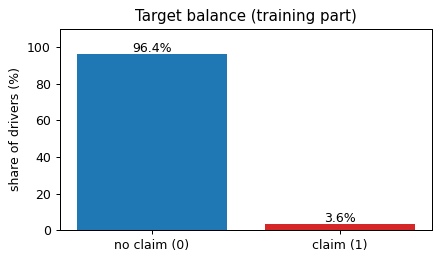

In [6]:
# 5. Class distribution of the target (training part)
class_counts = y_train.value_counts().sort_index()
class_share = y_train.value_counts(normalize=True).sort_index()
print(pd.DataFrame({'count': class_counts, 'percent': (class_share * 100).round(2)}))

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['no claim (0)', 'claim (1)'], class_share * 100, color=['tab:blue', 'tab:red'])
for position, share in enumerate(class_share * 100):
    ax.text(position, share + 1, f"{share:.1f}%", ha='center')
ax.set_ylabel('share of drivers (%)')
ax.set_ylim(0, 110)
ax.set_title('Target balance (training part)')
plt.tight_layout()
plt.show()

**Observations:**
- Strong class imbalance: only 3.64% of the drivers filed a claim (about 1 in 27).
- A model that always predicts "no claim" reaches 96.4% accuracy, so accuracy is useless here.
  The competition metric, the normalised Gini (= 2·AUC − 1), only depends on the ranking of the
  predicted probabilities and is not affected by the imbalance; it is the main metric of the project,
  complemented by the precision-recall AUC.

## 6. Missing values

In [7]:
# 6. Count missing values per column (training part only)
missing_counts = train_data.isnull().sum()
missing_counts = missing_counts[missing_counts > 0]

missing_df = pd.DataFrame({
    'count': missing_counts,
    'percent': (missing_counts / len(train_data) * 100).round(2),
}).sort_values('percent', ascending=False)

print(missing_df)

                count  percent
ps_car_03_cat  329080    69.11
ps_car_05_cat  213124    44.76
ps_reg_03       86269    18.12
ps_car_14       34176     7.18
ps_car_07_cat    9161     1.92
ps_ind_05_cat    4607     0.97
ps_car_09_cat     458     0.10
ps_ind_02_cat     165     0.03
ps_car_01_cat      84     0.02
ps_ind_04_cat      62     0.01
ps_car_02_cat       4     0.00
ps_car_11           5     0.00


Three columns are heavily missing: `ps_car_03_cat` (69%), `ps_car_05_cat` (45%) and `ps_reg_03` (18%).
`ps_car_14` is moderately missing (7%), and all others are under 2%.
Dropping rows with missing values is not an option (it would remove most of the data).
Whether to drop a heavily missing column, or keep it and add a "was missing" flag, depends on whether
missingness is related to the target:

In [8]:
# 6. Claim rate when a value is missing vs present (training part only)
rows = []
for col in missing_df.index:
    is_missing = train_data[col].isnull()
    rows.append({
        'column': col,
        'n_missing': is_missing.sum(),
        'claim_rate_missing': train_data.loc[is_missing, 'target'].mean(),
        'claim_rate_present': train_data.loc[~is_missing, 'target'].mean(),
    })

missing_target_df = pd.DataFrame(rows).set_index('column').round(4)
print(missing_target_df)

               n_missing  claim_rate_missing  claim_rate_present
column                                                          
ps_car_03_cat     329080              0.0328              0.0447
ps_car_05_cat     213124              0.0320              0.0401
ps_reg_03          86269              0.0283              0.0382
ps_car_14          34176              0.0401              0.0362
ps_car_07_cat       9161              0.0784              0.0356
ps_ind_05_cat       4607              0.0803              0.0360
ps_car_09_cat        458              0.0852              0.0364
ps_ind_02_cat        165              0.1818              0.0364
ps_car_01_cat         84              0.2976              0.0364
ps_ind_04_cat         62              0.3871              0.0364
ps_car_02_cat          4              0.0000              0.0364
ps_car_11              5              0.0000              0.0364


**Observations:**
- Missingness is informative: when `ps_car_03_cat`, `ps_car_05_cat` or `ps_reg_03` is missing, the claim
  rate is 20–27% lower; when `ps_car_07_cat` or `ps_ind_05_cat` is missing, it is about twice as high
  (≈8% vs 3.6%).
- For the very rarely missing columns (`ps_ind_02_cat`, `ps_car_01_cat`, `ps_ind_04_cat`) the claim rate
  among the missing rows is very high (18–39%), but it is based on fewer than 200 rows each.
- Decision: no column and no row is dropped because of missing values; "missing" is kept as information
  (own category for categorical features, indicator for numeric ones).

## 7. Feature types and distributions
Group by name prefix (`ind`, `reg`, `car`, `calc`) and type by suffix
(`_bin` = binary, `_cat` = categorical, no suffix = numeric).

In [9]:
# 7. Feature group and type from the column names
feature_info = pd.DataFrame({
    'group': [col.split('_')[1] for col in X_train.columns],
    'type': ['bin' if col.endswith('_bin') else 'cat' if col.endswith('_cat') else 'numeric'
             for col in X_train.columns],
}, index=X_train.columns)

# number of features per group and type
print(pd.crosstab(feature_info['group'], feature_info['type'], margins=True))

type   bin  cat  numeric  All
group                        
calc     6    0       14   20
car      0   11        5   16
ind     11    3        4   18
reg      0    0        3    3
All     17   14       26   57


In [10]:
# 7. Number of categories per categorical feature (missing not counted)
cat_cols = feature_info[feature_info['type'] == 'cat'].index
print(X_train[cat_cols].nunique().sort_values(ascending=False))

ps_car_11_cat    104
ps_car_06_cat     18
ps_car_01_cat     12
ps_car_04_cat     10
ps_ind_05_cat      7
ps_car_09_cat      5
ps_ind_02_cat      4
ps_car_10_cat      3
ps_ind_04_cat      2
ps_car_02_cat      2
ps_car_03_cat      2
ps_car_05_cat      2
ps_car_07_cat      2
ps_car_08_cat      2
dtype: int64


In [11]:
# 7. Numeric features: number of distinct values and range
num_cols = feature_info[feature_info['type'] == 'numeric'].index

num_summary = pd.DataFrame({
    'n_unique': X_train[num_cols].nunique(),
    'min': X_train[num_cols].min(),
    'max': X_train[num_cols].max(),
}).sort_values('n_unique')

print(num_summary)

            n_unique       min        max
ps_car_11          4  0.000000   3.000000
ps_ind_14          5  0.000000   4.000000
ps_calc_04         6  0.000000   5.000000
ps_calc_05         7  0.000000   6.000000
ps_calc_09         8  0.000000   7.000000
ps_ind_01          8  0.000000   7.000000
ps_calc_02        10  0.000000   0.900000
ps_calc_01        10  0.000000   0.900000
ps_calc_03        10  0.000000   0.900000
ps_calc_07        10  0.000000   9.000000
ps_reg_01         10  0.000000   0.900000
ps_calc_06        11  0.000000  10.000000
ps_calc_12        11  0.000000  10.000000
ps_calc_08        11  2.000000  12.000000
ps_ind_03         12  0.000000  11.000000
ps_ind_15         14  0.000000  13.000000
ps_calc_13        14  0.000000  13.000000
ps_car_15         15  0.000000   3.741657
ps_reg_02         19  0.000000   1.800000
ps_calc_11        20  0.000000  19.000000
ps_calc_14        23  0.000000  22.000000
ps_calc_10        26  0.000000  25.000000
ps_car_12        176  0.100000   1

**Distributions:** one plot per variable — histograms for the numeric features, frequency bars for the
categorical features and the share of ones for the binary features.

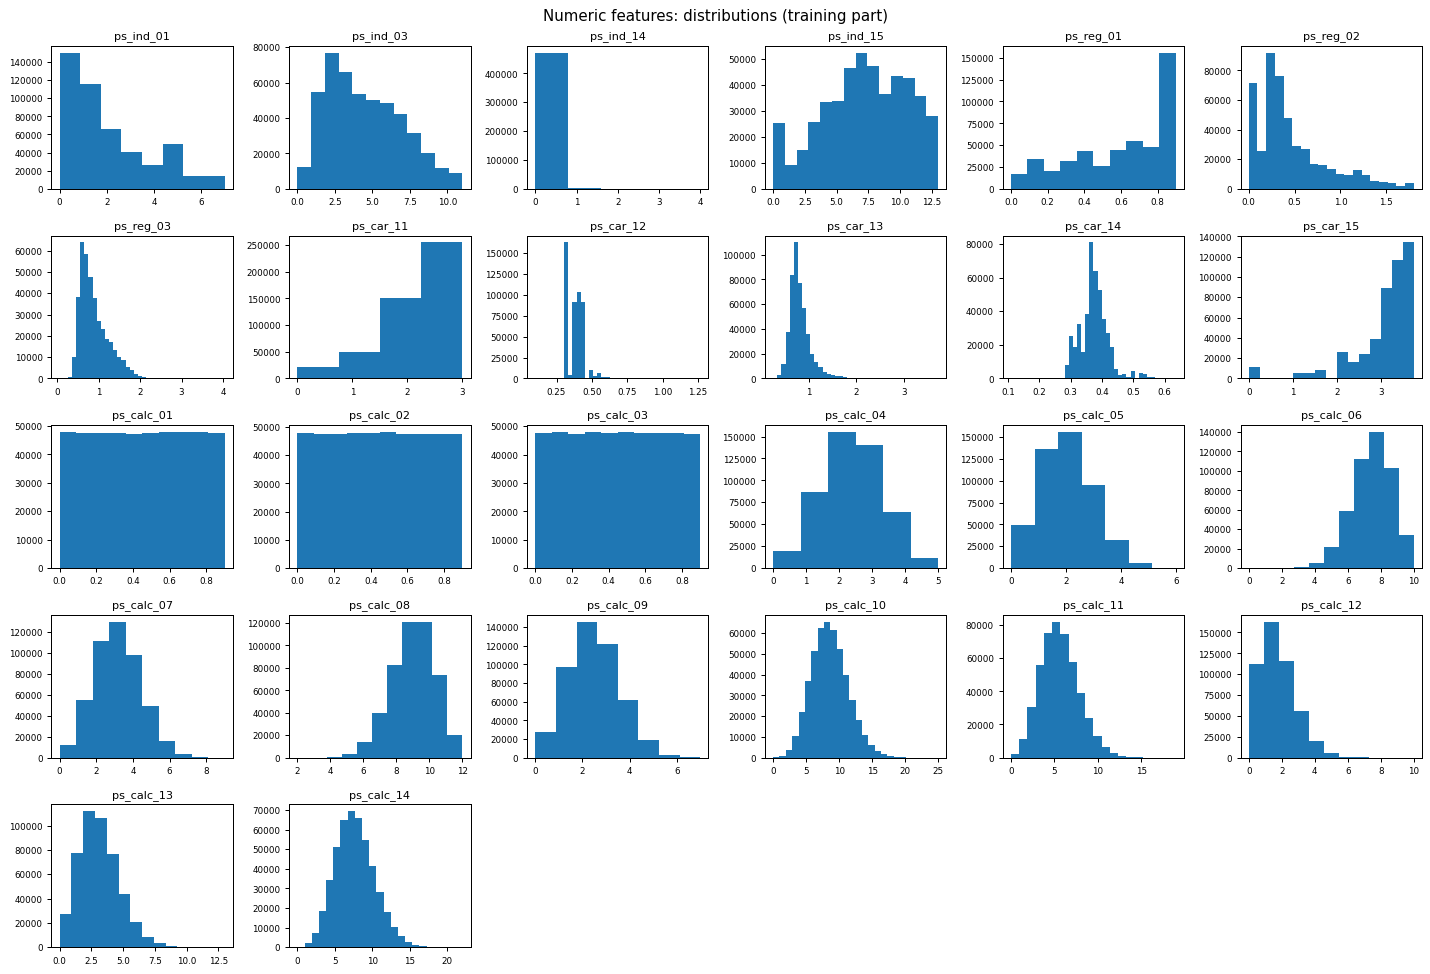

In [12]:
# 7. Histograms of the 26 numeric features (training part)
fig, axes = plt.subplots(5, 6, figsize=(16, 11))
for ax, col in zip(axes.flat, num_cols):
    values = X_train[col].dropna()
    # few distinct values: one bar per value; otherwise 40 bins
    n_bins = int(values.nunique()) if values.nunique() <= 30 else 40
    ax.hist(values, bins=n_bins, color='tab:blue')
    ax.set_title(col, fontsize=9)
    ax.tick_params(labelsize=7)
for ax in axes.flat[len(num_cols):]:
    ax.axis('off')
fig.suptitle('Numeric features: distributions (training part)')
plt.tight_layout()
plt.show()

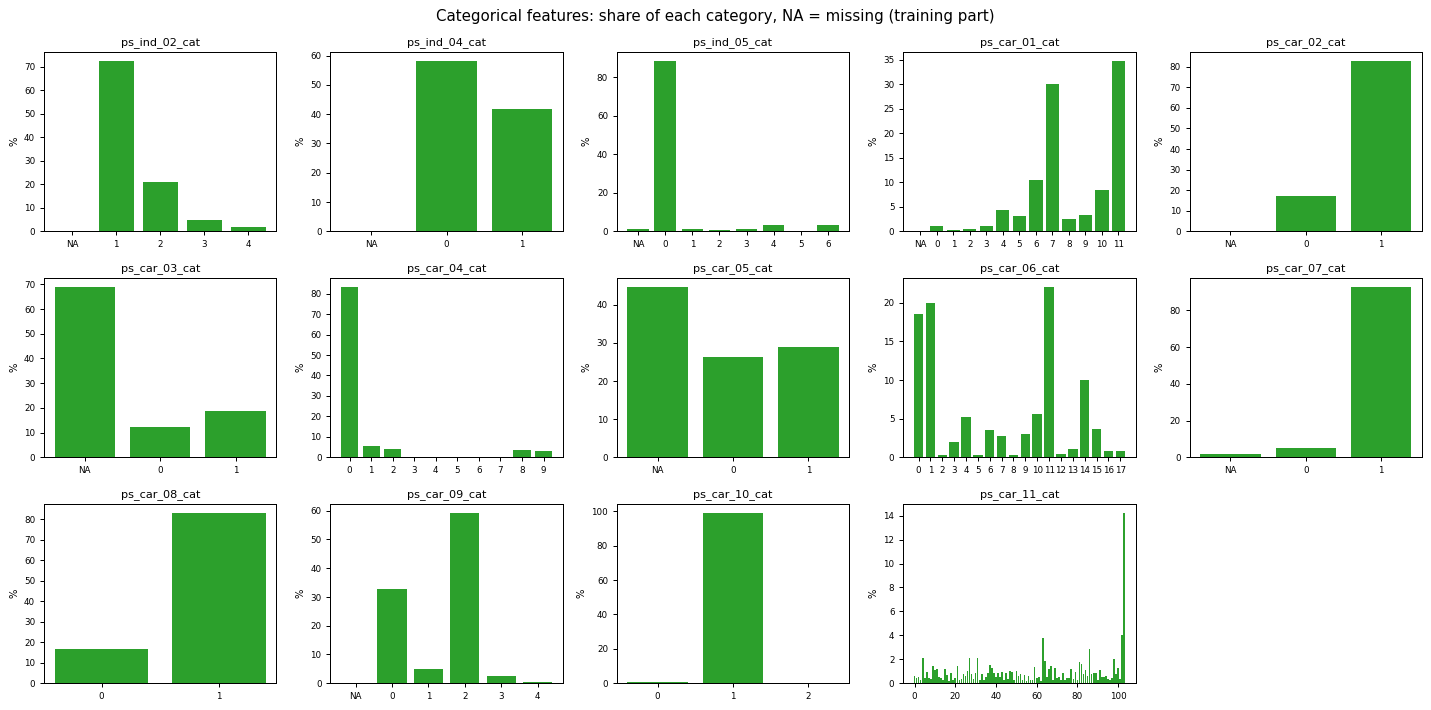

In [13]:
# 7. Frequency of each category (missing shown as 'NA') for the 14 categorical features
fig, axes = plt.subplots(3, 5, figsize=(16, 8))
for ax, col in zip(axes.flat, cat_cols):
    shares = X_train[col].fillna(-1).value_counts(normalize=True).sort_index()
    labels = ['NA' if value == -1 else str(int(value)) for value in shares.index]
    ax.bar(range(len(shares)), shares * 100, color='tab:green')
    # label every category only when there are few of them
    if len(shares) <= 20:
        ax.set_xticks(range(len(shares)))
        ax.set_xticklabels(labels, fontsize=7)
    ax.set_title(col, fontsize=9)
    ax.set_ylabel('%', fontsize=8)
    ax.tick_params(labelsize=7)
for ax in axes.flat[len(cat_cols):]:
    ax.axis('off')
fig.suptitle('Categorical features: share of each category, NA = missing (training part)')
plt.tight_layout()
plt.show()

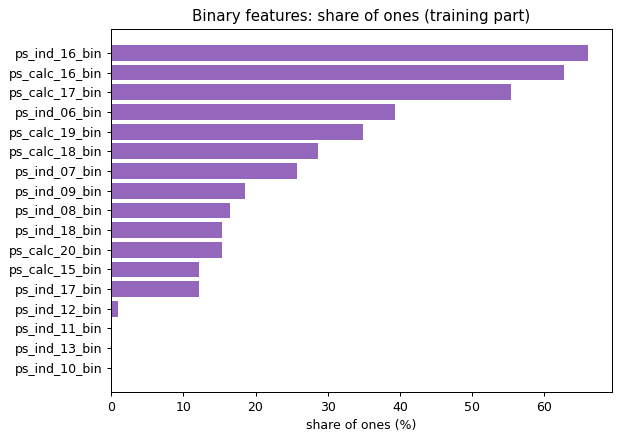

In [14]:
# 7. Share of ones for the 17 binary features
bin_cols = feature_info[feature_info['type'] == 'bin'].index
share_of_ones = (X_train[bin_cols].mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(share_of_ones.index, share_of_ones, color='tab:purple')
ax.set_xlabel('share of ones (%)')
ax.set_title('Binary features: share of ones (training part)')
plt.tight_layout()
plt.show()

In [15]:
# 7. Near-constant features: share of the most frequent value (missing counted as a value)
top_value_share = X_train.apply(lambda col: col.value_counts(normalize=True, dropna=False).iloc[0])
print(top_value_share.sort_values(ascending=False).head(6).round(4))

# ps_car_15 has only 15 distinct values: are they square roots of integers?
car_15_squared = X_train['ps_car_15'].dropna() ** 2
print("\nps_car_15 squared:", np.sort(car_15_squared.round(6).unique()))

ps_ind_10_bin    0.9996
ps_ind_13_bin    0.9991
ps_ind_11_bin    0.9983
ps_car_10_cat    0.9915
ps_ind_12_bin    0.9906
ps_ind_14        0.9893
dtype: float64

ps_car_15 squared: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14.]


**Observations:**
- Continuous features are right-skewed (`ps_car_13`, `ps_reg_02`, `ps_reg_03`); this matters for
  logistic regression (standardization), not for trees.
- `ps_car_15` takes only 15 values, which are exactly the square roots of the integers 0–14: it is a
  disguised count. `ps_car_12` is also concentrated on a few values.
- `ps_calc_01` to `ps_calc_03` are perfectly uniform on 0.0–0.9, and the other `calc` features look like
  synthetic counts: another hint that the `calc` group is artificial (confirmed in section 8).
- Near-constant features: `ps_ind_10_bin` to `ps_ind_13_bin` (and hence their sum `ps_ind_14`) and
  `ps_car_10_cat` have the same value in more than 99% of the rows, so they can carry little information.
- `ps_car_11_cat` is dominated by category 104 (14%); most of its other 103 categories hold under 2% each,
  so rare categories must be grouped before one-hot encoding.

## 8. Features vs target
Univariate Gini per feature: each value is replaced by its claim rate
(continuous features binned into 20 quantiles, missing = own value).
A random noise feature serves as the "no signal" reference.

In [16]:
# 8. Univariate Gini of a single feature
def univariate_gini(feature, target, n_bins=20):
    """Gini (2*AUC - 1) obtained by scoring each row with the claim rate of its feature value."""
    values = feature.copy()
    # bin continuous features, otherwise every value would be its own group
    if values.nunique() > 50:
        values = pd.qcut(values, q=n_bins, duplicates='drop')
    # missing values become their own group 'missing'
    values = values.astype(object).fillna('missing').astype(str)
    claim_rate = target.groupby(values).mean()
    score = values.map(claim_rate)
    return 2 * roc_auc_score(target, score) - 1

In [17]:
# 8. Univariate Gini for all features and for a random noise feature
rng = np.random.default_rng(RANDOM_STATE)
noise = pd.Series(rng.integers(0, 10, len(train_data)), index=train_data.index)
noise_gini = univariate_gini(noise, train_data['target'])

rows = []
for col in X_train.columns:
    rows.append({
        'feature': col,
        'group': feature_info.loc[col, 'group'],
        'type': feature_info.loc[col, 'type'],
        'gini': univariate_gini(train_data[col], train_data['target']),
    })
gini_df = pd.DataFrame(rows).set_index('feature').sort_values('gini', ascending=False)

print(f"Random noise feature: {noise_gini:.4f}\n")
print("Per group:")
print(gini_df.groupby('group')['gini'].agg(['mean', 'max']).round(4))
print("\nTop 15 features:")
print(gini_df.head(15).round(4))
print(f"\ncalc features above noise level: "
      f"{(gini_df.loc[gini_df['group'] == 'calc', 'gini'] > noise_gini).sum()} of 20")

Random noise feature: 0.0120

Per group:
         mean     max
group                
calc   0.0079  0.0191
car    0.0737  0.1525
ind    0.0376  0.0888
reg    0.1045  0.1180

Top 15 features:
              group     type    gini
feature                             
ps_car_13       car  numeric  0.1525
ps_reg_03       reg  numeric  0.1180
ps_reg_02       reg  numeric  0.1158
ps_car_12       car  numeric  0.1097
ps_car_01_cat   car      cat  0.1034
ps_car_14       car  numeric  0.0963
ps_car_15       car  numeric  0.0914
ps_ind_06_bin   ind      bin  0.0888
ps_ind_03       ind  numeric  0.0864
ps_car_06_cat   car      cat  0.0853
ps_car_11_cat   car      cat  0.0807
ps_reg_01       reg  numeric  0.0796
ps_car_03_cat   car      cat  0.0781
ps_ind_07_bin   ind      bin  0.0775
ps_car_04_cat   car      cat  0.0743

calc features above noise level: 5 of 20


In [18]:
# 8. Noise reference: how high can a pure-noise feature score by chance?
noise_ginis = []
for seed in range(20):
    rng = np.random.default_rng(seed)
    noise = pd.Series(rng.integers(0, 10, len(train_data)), index=train_data.index)
    noise_ginis.append(univariate_gini(noise, train_data['target']))
noise_ginis = np.array(noise_ginis)

print(f"Noise Gini over 20 draws: mean {noise_ginis.mean():.4f}, max {noise_ginis.max():.4f}")
print("\nBest calc features:")
print(gini_df.loc[gini_df['group'] == 'calc', 'gini'].head(5).round(4))

Noise Gini over 20 draws: mean 0.0118, max 0.0192

Best calc features:
feature
ps_calc_10    0.0191
ps_calc_01    0.0174
ps_calc_11    0.0143
ps_calc_14    0.0135
ps_calc_02    0.0133
Name: gini, dtype: float64


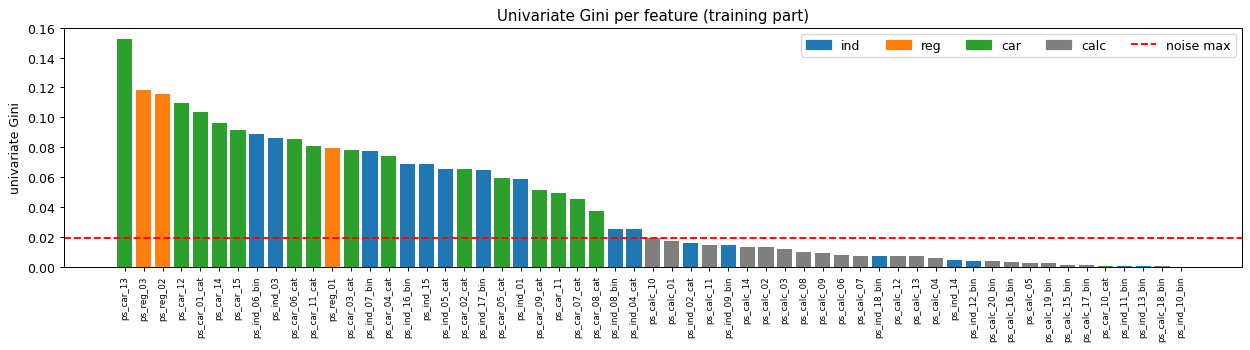

In [19]:
# 8. Univariate Gini of all features, coloured by group, with the noise maximum as reference
group_colors = {'ind': 'tab:blue', 'reg': 'tab:orange', 'car': 'tab:green', 'calc': 'tab:gray'}

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(gini_df.index, gini_df['gini'], color=gini_df['group'].map(group_colors))
ax.axhline(noise_ginis.max(), color='red', linestyle='--', label='max of 20 noise features')
ax.set_xticks(range(len(gini_df)))
ax.set_xticklabels(gini_df.index, rotation=90, fontsize=7)
ax.set_ylabel('univariate Gini')
handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in group_colors.values()]
ax.legend(handles + [ax.lines[0]], list(group_colors) + ['noise max'], ncol=5)
ax.set_title('Univariate Gini per feature (training part)')
plt.tight_layout()
plt.show()

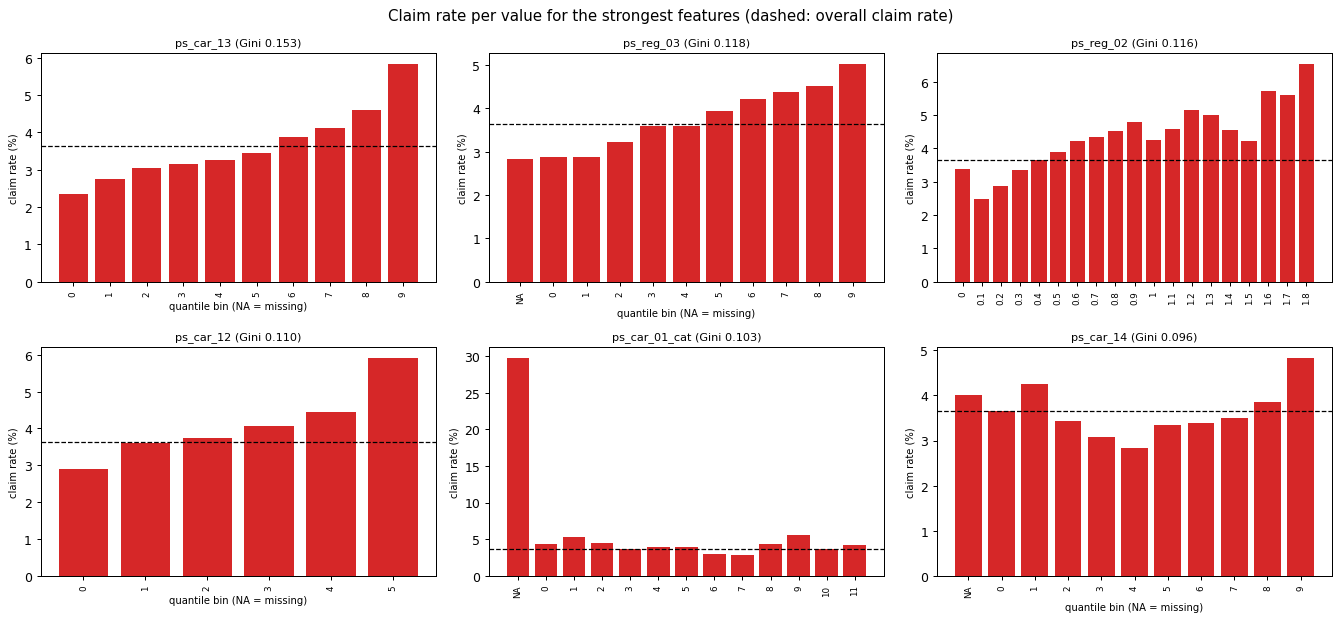

In [20]:
# 8. Claim rate per value for the six strongest features (continuous ones binned into quantiles)
overall_claim_rate = train_data['target'].mean()
top_features = gini_df.index[:6]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flat, top_features):
    values = train_data[col]
    if values.nunique() > 50:
        # decile number 0..9; missing values get the code -1
        values = pd.qcut(values, q=10, duplicates='drop').cat.codes
        ax.set_xlabel('quantile bin (NA = missing)', fontsize=8)
    groups = values.fillna(-1)
    claim_rate = train_data['target'].groupby(groups).mean() * 100
    labels = ['NA' if value == -1 else str(int(value)) if float(value).is_integer() else f"{value:g}"
              for value in claim_rate.index]
    ax.bar(range(len(claim_rate)), claim_rate, color='tab:red')
    ax.axhline(overall_claim_rate * 100, color='black', linestyle='--', linewidth=1)
    if len(claim_rate) <= 25:
        ax.set_xticks(range(len(claim_rate)))
        ax.set_xticklabels(labels, fontsize=7, rotation=90)
    ax.set_title(f"{col} (Gini {gini_df.loc[col, 'gini']:.3f})", fontsize=9)
    ax.set_ylabel('claim rate (%)', fontsize=8)
fig.suptitle('Claim rate per value for the strongest features (dashed: overall claim rate)')
plt.tight_layout()
plt.show()

**Observations:**
- No feature is strong on its own: the best univariate Gini is 0.15 (`ps_car_13`).
  The signal is spread over many weak features, so models that combine features are needed.
- The `reg` features and the continuous `car` features (`ps_car_12` to `ps_car_15`) are the strongest.
- `ps_car_03_cat` reaches 0.078 despite 69% missing values: its signal comes mostly from missingness (section 6).
- The `calc` features are indistinguishable from random noise: the best `calc` feature (0.0191) stays
  below the maximum of 20 random noise features (0.0192). They are a candidate for removal;
  this is confirmed later with an ablation study (CV Gini with vs. without `calc`, notebook 03).
- The claim rate rises steadily with `ps_car_13`, `ps_reg_02`, `ps_reg_03` and `ps_car_12`
  (from about 2.5–3% in the lowest to 5–6.5% in the highest bins): roughly monotonic, suitable also for a
  linear model.
- `ps_car_14` is U-shaped (higher claim rate at both ends): a linear model cannot capture this, trees can.
- For `ps_car_01_cat` the signal comes almost entirely from the missing category (claim rate ≈ 30%,
  but only 84 rows); the 12 regular categories stay close to the average.

## 9. Correlations between features
Spearman correlation of the binary and numeric features (without `calc`, see section 8).
Nominal categorical features are excluded, because correlations of category codes are not meaningful.

In [21]:
# 9. Spearman correlation of binary and numeric features (without calc)
corr_cols = feature_info[(feature_info['group'] != 'calc') &
                         (feature_info['type'] != 'cat')].index
corr = train_data[corr_cols].corr(method='spearman')

# the 10 most strongly correlated pairs (each pair counted once)
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
top_pairs = pairs.abs().sort_values(ascending=False).head(10).index
print(pairs.loc[top_pairs].round(3))

ps_ind_12_bin  ps_ind_14        0.939
ps_reg_02      ps_reg_03        0.686
ps_car_13      ps_car_15        0.677
ps_car_12      ps_car_13        0.664
ps_ind_16_bin  ps_ind_18_bin   -0.594
ps_car_12      ps_car_14        0.554
ps_reg_01      ps_reg_02        0.537
ps_ind_16_bin  ps_ind_17_bin   -0.518
ps_ind_06_bin  ps_ind_07_bin   -0.473
ps_ind_15      ps_ind_18_bin   -0.421
dtype: float64


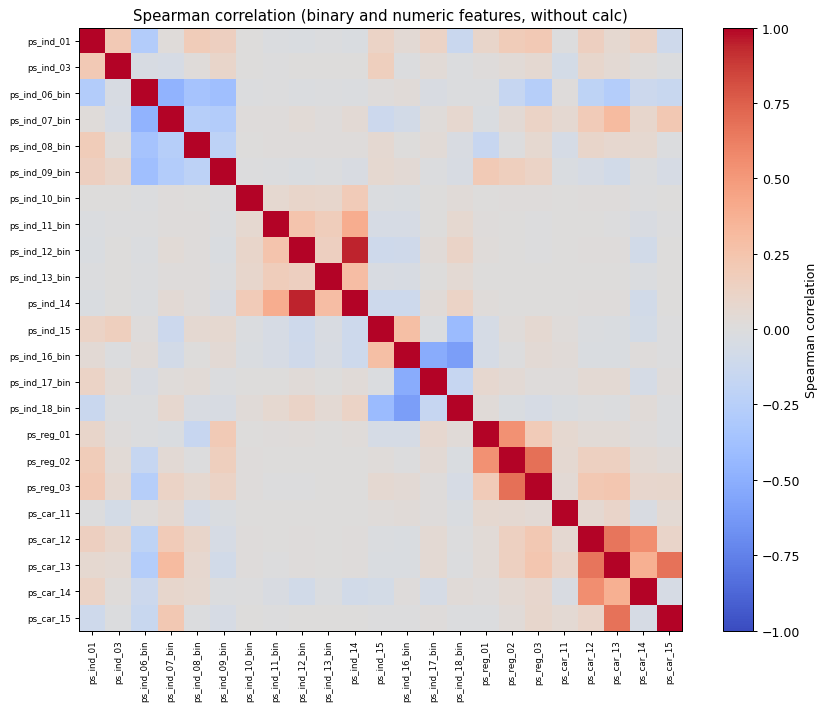

In [22]:
# 9. Heatmap of the correlation matrix
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns, fontsize=7)
fig.colorbar(image, ax=ax, label='Spearman correlation')
ax.set_title('Spearman correlation (binary and numeric features, without calc)')
plt.tight_layout()
plt.show()

In [23]:
# 9. Check: is ps_ind_14 the count of ps_ind_10_bin ... ps_ind_13_bin?
ind_10_13 = ['ps_ind_10_bin', 'ps_ind_11_bin', 'ps_ind_12_bin', 'ps_ind_13_bin']
share_equal = (train_data[ind_10_13].sum(axis=1) == train_data['ps_ind_14']).mean()
print(f"ps_ind_14 equals the sum of ind_10..13 in {share_equal:.2%} of rows\n")

# Check: are ind_06..09 and ind_16..18 one-hot blocks (exactly one is 1 per row)?
ind_06_09 = ['ps_ind_06_bin', 'ps_ind_07_bin', 'ps_ind_08_bin', 'ps_ind_09_bin']
ind_16_18 = ['ps_ind_16_bin', 'ps_ind_17_bin', 'ps_ind_18_bin']
print("Number of ones in ind_06..09 per row:")
print(train_data[ind_06_09].sum(axis=1).value_counts())
print("\nNumber of ones in ind_16..18 per row:")
print(train_data[ind_16_18].sum(axis=1).value_counts())

ps_ind_14 equals the sum of ind_10..13 in 100.00% of rows

Number of ones in ind_06..09 per row:
1    476169
Name: count, dtype: int64

Number of ones in ind_16..18 per row:
1    445355
0     30814
Name: count, dtype: int64


**Observations:**
- Only one pair is redundant (|r| > 0.85): `ps_ind_12_bin` and `ps_ind_14` (r = 0.94).
  The check shows why: `ps_ind_14` is exactly the sum of `ps_ind_10_bin` to `ps_ind_13_bin`
  (100% of rows), i.e. a derived count feature without new information.
- `ps_ind_06_bin` to `ps_ind_09_bin` form a perfect one-hot encoding: every row has exactly one 1.
  They represent one hidden categorical variable with four categories.
- `ps_ind_16_bin` to `ps_ind_18_bin` form a one-hot encoding with a reference category:
  93.5% of the rows have exactly one 1, 6.5% have none (the fourth category).
- Moderate correlations exist within the `reg` features (0.54–0.69) and within the continuous
  `car` features (0.55–0.68); most other pairs are close to 0.

**Decisions:**
- Tree models (random forest, gradient boosting): keep all features, since redundancy does not hurt trees.
- Logistic regression: drop `ps_ind_14`, because it is an exact linear combination of four other
  features (perfect multicollinearity). The one-hot block `ps_ind_06–09` is handled by the
  L2 regularization.
- The correlations are kept in mind when interpreting the logistic regression weights,
  since correlated features share their weight.

## 10. Duplicates
Check whether rows occur more than once, and whether duplicates fall into both the training
and the test part (leakage risk: the same individual in training and test).

In [24]:
# 10. Is every id unique? (one row per policy)
print("All ids unique:", data['id'].is_unique)

# one hash value per row, so identical rows get the same value (NaN handled consistently)
row_key = pd.util.hash_pandas_object(features, index=False)
print("Exact duplicate rows (all 57 features):", row_key.duplicated().sum())

# same check without the calc features
non_calc_cols = feature_info[feature_info['group'] != 'calc'].index
row_key_no_calc = pd.util.hash_pandas_object(features[non_calc_cols], index=False)
print("Duplicate rows without calc features:", row_key_no_calc.duplicated().sum())

# duplicates that ended up in both the training and the test part
overlap = (set(row_key_no_calc.loc[X_train.index])
           & set(row_key_no_calc.loc[X_test.index]))
print("Feature rows (without calc) present in both train and test:", len(overlap))

All ids unique: True


Exact duplicate rows (all 57 features): 0


Duplicate rows without calc features: 6


Feature rows (without calc) present in both train and test: 0


**Observations:**
- All ids are unique: each row is one policy.
- There are no exact duplicate rows. Ignoring the `calc` features, 6 rows are duplicates
  (0.001% of the data), and none of them fall into both the training and the test part.
- Decision: no leakage risk from duplicates; the row-wise stratified split is valid.

## 11. Summary of findings

**Data and split**
- 595,212 rows, 57 features (17 binary, 14 categorical, 26 numeric) plus `id` and `target`.
- Strong class imbalance: only 3.64% of the drivers filed a claim (section 5); accuracy is not a useful
  metric, the normalised Gini and the PR-AUC are used instead.
- Stratified 80/20 split: the claim rate is 3.645% in both the training and the test part.
- Missing values are coded as -1; this is the only negative value, so it was safely replaced by NaN.
- All ids are unique, and no duplicates fall into both parts: no leakage risk from the split.

**Missing values**
- Heavily missing: `ps_car_03_cat` (69%), `ps_car_05_cat` (45%), `ps_reg_03` (18%).
- Missingness is informative: when `ps_car_03_cat`, `ps_car_05_cat` or `ps_reg_03` is missing,
  the claim rate is 20–27% lower; when `ps_car_07_cat` or `ps_ind_05_cat` is missing, it is about
  twice as high (≈8% vs 3.6%). No column and no row is dropped because of missing values.

**Feature types and structure**
- `ps_car_11_cat` has 104 categories; all other categorical features have at most 18.
- Near-constant: `ps_ind_10–13_bin`, `ps_ind_14` and `ps_car_10_cat` (>99% one value).
- Continuous features are right-skewed; `ps_car_14` has a U-shaped relation with the target.
- `ps_ind_14` is exactly the sum of `ps_ind_10_bin` to `ps_ind_13_bin`.
- `ps_ind_06–09_bin` and `ps_ind_16–18_bin` are one-hot encoded hidden categorical variables.
- No other pair of features is redundant (all other |r| < 0.7).

**Features vs target**
- No feature is strong on its own: the best univariate Gini is 0.15 (`ps_car_13`).
  The signal is spread over many weak features.
- The strongest features are the `reg` features and the continuous `car` features.
- The 20 `calc` features are indistinguishable from random noise: the best `calc` feature
  (Gini 0.0191) stays below the maximum of 20 random noise features (0.0192).

**EDA log**
| Finding | Evidence | Decision | Status |
|---|---|---|---|
| Missing coded as -1 | competition description; only negative value (section 3) | recode as NaN before the split | done |
| Strong class imbalance (3.64%) | section 5 | Gini and PR-AUC instead of accuracy; stratified split and CV | done |
| Missingness is informative | claim rate missing vs present (section 6) | missing category for `_cat`; median + indicator for numeric (LR); NaN kept for gradient boosting | notebook 02 |
| `ps_car_11_cat` has 104 levels | section 7 | one-hot with rare levels grouped | notebook 02 |
| Near-constant features | >99% one value (section 7) | keep for trees; little effect expected, check with feature importance | notebook 03 |
| Skewed continuous features, U-shape of `ps_car_14` | sections 7–8 | standardize for LR; non-linear models expected to do better | notebook 03 |
| `calc` features ≈ noise | univariate Gini vs 20 noise draws (section 8) | candidate for removal; confirm with ablation | notebook 03 |
| No strong single feature | best univariate Gini 0.15 (section 8) | models that combine many features | noted |
| `ps_ind_14` = sum of `ind_10–13` | 100% of rows (section 9) | drop for logistic regression only | notebook 02 |
| One-hot blocks `ind_06–09`, `ind_16–18` | row sums (section 9) | keep; L2 regularization handles collinearity | noted |
| Duplicates | 0 exact, 6 without `calc`, none across the split (section 10) | row-wise split is valid | done |

**Next steps:** notebook 02 builds the preparation pipelines from this log; notebook 03 compares the models
with cross-validation on the training part; notebook 04 evaluates the final model once on the test part.